# Customer Churn & Retention Analysis
###  Python & Pandas Exploration

**Objective:** Explore customer data, understand its structure, identify patterns, and investigate factors associated with customer churn.

In [1]:
# Check which Python installation is running this notebook
import sys
print(sys.executable)

c:\Users\cutes\AppData\Local\Programs\Python\Python313\python.exe


In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("E:\\My Project\\Customer-churn-analysis\\data\\raw\\Telco-Customer-Churn.csv")
#df = pd.read_csv("E:\\My Project\\Customer-churn-analysis\\data\\incoming\\Telco-Customer-Churn-New.csv")

In [4]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


---
## 2. Dataset Overview

Let's inspect the dataset's dimensions to understand how many customer records and columns are available.

In [5]:
df.shape

(7043, 21)

In [6]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [7]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
df.head(10)  # First 10 rows

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [9]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### 2.2 Dataset Structure and Data Types



### 2.3 Checking Missing Values

Missing values can affect calculations and analysis. We will identify columns containing missing values before deciding how to handle them.

In [11]:
df.isnull().sum()  # Check for missing values

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

### 2.3.1 Interpreting Missing Values

In [12]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

### 2.4 Investigating the TotalCharges Column


In [13]:
df[df["TotalCharges"].str.strip() == ""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


### 2.4.1 Findings: Blank TotalCharges Records


**Possible explanation:** These customers may have recently joined the service. Since their tenure is zero, they may not yet have accumulated a recorded total charge.

## 3. Exploring Numerical Variables


In [14]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


### 3.1 Statistical Summary



**Note:** `TotalCharges` is not included in the numerical summary because it is stored as a string rather than a numeric data type. We will address this during data cleaning.

## 4. Exploring Categorical Variables

Categorical variables describe customer groups and service choices.

We will examine their frequency distributions to understand how customers are distributed across different categories.

In [15]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

### 4.1 Customer Churn Distribution


In [16]:
df["Churn"].value_counts(normalize=True)  # Proportion of churned vs non-churned customers

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

### 4.2 Customer Churn Rate


In [17]:
df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

### 4.3 Contract Type Distribution


In [18]:
df["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

### 4.4 Payment Method Distribution


### 4.5 Internet Service Distribution

We will examine how customers are distributed across the available internet service categories.

In [19]:
df["InternetService"].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

### 4.5 Internet Service Distribution



## 5. Numerical Variable Exploration


In [20]:
df["tenure"].mean()  # Calculate the average customer tenure in months

np.float64(32.37114865824223)

In [21]:
df["MonthlyCharges"].mean()  # Calculate the average monthly charge

np.float64(64.76169246059918)

In [22]:
df["MonthlyCharges"].median()  # Calculate the median monthly charge

np.float64(70.35)

In [23]:
df["MonthlyCharges"].min()  # Find the lowest monthly charge

np.float64(18.25)

In [24]:
df["MonthlyCharges"].max()  # Find the highest monthly charge

np.float64(118.75)

### Section 5 Summary

We explored numerical customer variables using pandas.

Key findings:
- Average customer tenure is approximately 32.37 months.
- Average monthly charges are $64.76.
- Median monthly charges are $70.35.
- Monthly charges range from $18.25 to $118.75.

Methods learned:
- mean()
- median()
- min()
- max()

These statistics provide an overview of customer tenure and billing patterns. Further analysis will help us understand how these variables relate to customer churn.

## 6. Filtering and Sorting Customer Data

Filtering helps us find specific customers based on conditions. Sorting helps us arrange records to identify useful patterns.

We will use these techniques to investigate customer behaviour and prepare for group comparisons.

In [25]:
df[df["Churn"] == "Yes"] # Filter customers who have churned

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
13,0280-XJGEX,Male,0,No,No,49,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7021,1699-HPSBG,Male,0,No,No,12,Yes,No,DSL,No,...,No,Yes,Yes,No,One year,Yes,Electronic check,59.80,727.8,Yes
7026,8775-CEBBJ,Female,0,No,No,9,Yes,No,DSL,No,...,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),44.20,403.35,Yes
7032,6894-LFHLY,Male,1,No,No,1,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,75.75,75.75,Yes
7034,0639-TSIQW,Female,0,No,No,67,Yes,Yes,Fiber optic,Yes,...,Yes,No,Yes,No,Month-to-month,Yes,Credit card (automatic),102.95,6886.25,Yes


In [26]:
# Select month-to-month customers and display customerID and tenure
df.loc[df["Contract"] == "Month-to-month", ["customerID", "tenure"]]

,customerID,tenure
0,7590-VHVEG,1
2,3668-QPYBK,2
4,9237-HQITU,2
5,9305-CDSKC,8
6,1452-KIOVK,22
...,...,...
7033,9767-FFLEM,38
7034,0639-TSIQW,67
7035,8456-QDAVC,19
7040,4801-JZAZL,11


In [27]:
# Sort all customer records by tenure, highest to lowest
df.sort_values(by="tenure", ascending=False)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
3177,1814-WFGVS,Male,0,Yes,Yes,72,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Mailed check,48.90,3527,No
3131,8336-TAVKX,Female,1,Yes,No,72,Yes,Yes,DSL,Yes,...,Yes,Yes,No,Yes,Two year,No,Bank transfer (automatic),78.45,5682.25,No
3107,5038-ETMLM,Female,0,Yes,No,72,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),113.65,8182.75,No
35,6234-RAAPL,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,...,No,Yes,Yes,No,Two year,No,Bank transfer (automatic),99.90,7251.7,No
3111,8809-RIHDD,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Two year,Yes,Electronic check,103.40,7372.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No


In [28]:
# Count customers in each contract type
df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

We will compare customer churn across different contract types to identify which group has a higher proportion of customers leaving the service.

In [29]:
# Compare churn counts across different contract types
pd.crosstab(df["Contract"], df["Churn"])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [30]:
# Calculate the percentage of churned customers within each contract type
pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
# normalize="index" converts the counts into percentages for each row

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


### Findings: Churn by Contract Type

We compared customer churn across the three contract types.

Key observations:
- Month-to-month customers have the highest churn rate at 42.71%.
- One-year contract customers have a churn rate of 11.27%.
- Two-year contract customers have the lowest churn rate at 2.83%.

**Business Insight:** Customers with month-to-month contracts are more likely to leave than customers with longer-term contracts.

This suggests that contract type is an important factor to investigate when studying customer churn. However, this comparison alone does not establish causation.

# Customer Churn & Retention Analysis
### Phase 3: Data Cleaning

**Objective:** Prepare the raw customer dataset for reliable analysis by identifying and handling missing values, duplicate records, incorrect data types, and inconsistent or suspicious values.

The original raw dataset will remain unchanged. All cleaning operations will be performed on a separate working copy.

In [31]:
# Create a working copy of the raw dataset
df_clean = df.copy()

## 1. Checking Missing Values

Missing values can affect calculations and analysis. We will identify which columns contain missing values and how many records are affected.

We will investigate these issues before deciding how to handle them.

In [32]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## 2. Investigating Blank TotalCharges Values

During Phase 2, we identified 11 records with blank or whitespace-only values in the `TotalCharges` column.

We will investigate these records to understand why the values are missing before deciding how to handle them.

In [33]:
# Filter records where TotalCharges contains blank or whitespace-only values
df_clean[df_clean["TotalCharges"].str.strip() == ""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [34]:
# Display tenure and churn status for customers with blank TotalCharges
df_clean.loc[
    df_clean["TotalCharges"].str.strip() == "",
    ["customerID", "tenure", "TotalCharges", "Churn"]
]

,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,,No
753,3115-CZMZD,0,,No
936,5709-LVOEQ,0,,No
1082,4367-NUYAO,0,,No
1340,1371-DWPAZ,0,,No
3331,7644-OMVMY,0,,No
3826,3213-VVOLG,0,,No
4380,2520-SGTTA,0,,No
5218,2923-ARZLG,0,,No
6670,4075-WKNIU,0,,No


### Findings: Blank TotalCharges Records

The investigation identified 11 records with blank or whitespace-only values in TotalCharges.

Observations:
- All 11 customers have zero tenure.
- All 11 customers have Churn = No.
- Their TotalCharges values are blank.

In [35]:
# Check monthly charges for customers with blank TotalCharges
df_clean.loc[
    df_clean["TotalCharges"].str.strip() == "",
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


### Additional Observation

All 11 customers with blank TotalCharges values have valid, positive MonthlyCharges values.

This suggests that these customers have an assigned monthly subscription charge, even though their cumulative charges are blank.

The reason for the missing TotalCharges values is not confirmed. We will consider this evidence before deciding how to handle them.

In [36]:
# Check the current data type of TotalCharges
df_clean["TotalCharges"].dtype

<StringDtype(storage='python', na_value=nan)>

In [37]:
# Temporarily convert TotalCharges values into numeric format
# Invalid values will be converted into NaN instead of raising an error
pd.to_numeric(df_clean["TotalCharges"], errors="coerce")

0         29.85
1       1889.50
2        108.15
3       1840.75
4        151.65
         ...   
7038    1990.50
7039    7362.90
7040     346.45
7041     306.60
7042    6844.50
Name: TotalCharges, Length: 7043, dtype: float64

In [38]:
# Count values that become missing during numeric conversion
pd.to_numeric(df_clean["TotalCharges"], errors="coerce").isnull().sum()

np.int64(11)

### Cleaning Decision: TotalCharges

We identified 11 blank values in TotalCharges.

Decision:
- Retain all 11 customer records.
- Keep their TotalCharges values as missing (NaN).
- Do not replace them with zero because the actual cumulative charges are unknown.
- Do not delete these records because the remaining customer information is valid.

Reason:
Preserving missing values avoids introducing assumptions or losing valid customer records.

In [39]:
# Convert TotalCharges to numeric while preserving missing values
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"], errors="coerce"
)

In [40]:
# Verify the updated data type and missing-value count
df_clean["TotalCharges"].dtype, df_clean["TotalCharges"].isnull().sum()

(dtype('float64'), np.int64(11))

In [41]:
# Check for duplicate rows in the cleaned working dataset
df_clean.duplicated().sum()

np.int64(0)

### Findings: Duplicate Records

The duplicate check identified zero fully duplicated rows in the working dataset.

No duplicate rows were found, so no records need to be removed at this stage.

In [42]:
# Check whether any customer IDs are duplicated
df_clean["customerID"].duplicated().sum()

np.int64(0)

In [43]:
# Display the data types of all columns
df_clean.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

In [44]:
# Display unique contract labels
df_clean["Contract"].unique()

<StringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str

In [45]:
# Display unique payment method categories
df_clean["PaymentMethod"].unique()

<StringArray>
[         'Electronic check',              'Mailed check',
 'Bank transfer (automatic)',   'Credit card (automatic)']
Length: 4, dtype: str

## Checking Category Consistency

We will inspect categorical columns to identify unexpected labels, inconsistent values, or extra spaces.

This helps ensure that customer groups are represented consistently before further analysis.

In [46]:
# Display unique values in important categorical columns
categorical_columns = [
    "gender", "Partner", "Dependents", "PhoneService",
    "MultipleLines", "InternetService", "OnlineSecurity",
    "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "Contract",
    "PaperlessBilling", "PaymentMethod", "Churn"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df_clean[column].unique())


gender:
<StringArray>
['Female', 'Male']
Length: 2, dtype: str

Partner:
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

Dependents:
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

PhoneService:
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

MultipleLines:
<StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str

InternetService:
<StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

OnlineSecurity:
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

OnlineBackup:
<StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

DeviceProtection:
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

TechSupport:
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

StreamingTV:
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

StreamingMovies:
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

Contract:
<StringArray>
['Month-to-month', 

In [47]:
# Check categorical columns for leading or trailing spaces
for column in categorical_columns:
    print(column, df_clean[column].str.strip().ne(df_clean[column]).sum())

gender 0
Partner 0
Dependents 0
PhoneService 0
MultipleLines 0
InternetService 0
OnlineSecurity 0
OnlineBackup 0
DeviceProtection 0
TechSupport 0
StreamingTV 0
StreamingMovies 0
Contract 0
PaperlessBilling 0
PaymentMethod 0
Churn 0


### Findings: Category Consistency

All 16 categorical columns were checked for leading and trailing spaces.

The check identified zero values containing extra spaces.

No trimming or category-label corrections are required.

In [48]:
# Display minimum and maximum values of numerical columns
df_clean[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


## Cleaning Log

This section documents the data quality issues identified during Phase 3, the decisions taken, and the reasons behind those decisions.

| Issue | Evidence | Decision | Reason | Affected Records |
|---|---|---|---|---:|
| Missing TotalCharges | 11 blank values; all had tenure = 0 | Retained records, converted TotalCharges to float64, and kept missing values as NaN | Customers may be new, and their other information is valid. Actual cumulative charges are unknown. | 11 |
| Duplicate records and customer IDs | 0 duplicate rows and 0 duplicate customer IDs | No records removed | Every customer has a unique ID, and no fully duplicated records were found. | 0 |
| Incorrect data type | TotalCharges was stored as string | Converted to float64 | Allows mathematical calculations such as average and total charges | 7,043 |
| Category consistency | 16 categorical columns checked; no extra spaces or unexpected labels identified | No changes required | Existing category labels are consistent and suitable for analysis | 0 |
| Numerical range validation | tenure: 0–72; MonthlyCharges: 18.25–118.75; TotalCharges: 18.80–8,684.80 | No changes required | No obviously invalid numerical ranges were identified | 0 |

## Saving the Cleaned Dataset

After completing the data cleaning process, we will save the cleaned dataset separately in the `data/processed/` folder.

The original raw dataset will remain unchanged.

In [49]:
# Save the cleaned dataset in the processed folder
df_clean.to_csv(
    r"E:\My Project\Customer-churn-analysis\data\processed\Telco-Customer-Churn-Clean.csv",
    index=False
)

## Verifying the Cleaned Dataset

We will reload the saved CSV file to confirm that it was saved correctly and that the cleaned data has been preserved.

In [50]:
df_check = df_clean
print("Dataset shape:", df_check.shape)
print("Missing TotalCharges:", df_check["TotalCharges"].isnull().sum())
print("TotalCharges data type:", df_check["TotalCharges"].dtype)

Dataset shape: (7043, 21)
Missing TotalCharges: 11
TotalCharges data type: float64


In [51]:
# Calculate churn rate for each contract type
contract_churn = df_clean.groupby("Contract")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
).round(2)

print(contract_churn)

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


In [52]:
# Create the same tenure groups used in SQL
df_clean["tenure_group"] = pd.cut(
    df_clean["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"]
)

# Calculate customer count, churned customers, and churn rate
tenure_churn = df_clean.groupby("tenure_group", observed=True)["Churn"].agg(
    total_customers="count",
    churned_customers=lambda x: (x == "Yes").sum(),
    churn_rate=lambda x: (x == "Yes").mean() * 100
)

# Round churn rate to two decimal places
tenure_churn["churn_rate"] = tenure_churn["churn_rate"].round(2)

print(tenure_churn)

              total_customers  churned_customers  churn_rate
tenure_group                                                
0-12 months              2186               1037       47.44
13-24 months             1024                294       28.71
25-48 months             1594                325       20.39
49-72 months             2239                213        9.51



## Cross-Validation: SQL vs Python

**Objective:** Verify the tenure-based churn analysis performed in MySQL by comparing the results with calculations in Python.

Cross-validation helps ensure that our calculations are consistent and reliable across both tools.

**Metrics to compare:**
- Total customers in each tenure group.
- Number of churned customers in each group.
- Churn rate (%) for each group.

**Expected SQL results:**

| Tenure Group | Total Customers | Churned Customers | Churn Rate |
|---|---:|---:|---:|
| 0–12 months | 2,186 | 1,037 | 47.44% |
| 13–24 months | 1,024 | 294 | 28.71% |
| 25–48 months | 1,594 | 325 | 20.39% |
| 49–72 months | 2,239 | 213 | 9.51% |

**Validation Status:** Pending Python comparison.


In [53]:
# Create monthly charge groups
df_clean["charge_group"] = pd.cut(
    df_clean["MonthlyCharges"],
    bins=[0, 50, 85, float("inf")],
    labels=["Low", "Medium", "High"],
    right=True
)

# Calculate customer count, churned customers, and churn rate
charge_churn = df_clean.groupby("charge_group", observed=True)["Churn"].agg(
    total_customers="count",
    churned_customers=lambda x: (x == "Yes").sum(),
    churn_rate=lambda x: (x == "Yes").mean() * 100
)

# Round churn rate to two decimal places
charge_churn["churn_rate"] = charge_churn["churn_rate"].round(2)

# Display the results
print(charge_churn)

              total_customers  churned_customers  churn_rate
charge_group                                                
Low                      2299                361       15.70
Medium                   2556                768       30.05
High                     2188                740       33.82


## Cross-Validation: SQL vs Python — Monthly Charges

**Objective:** Verify the monthly charge-based churn analysis performed in MySQL using Python.

**Results:**

| Charge Group | Total Customers | Churned Customers | Churn Rate |
|---|---:|---:|---:|
| Low | 2,299 | 361 | 15.70% |
| Medium | 2,556 | 768 | 30.05% |
| High | 2,188 | 740 | 33.82% |

**Validation Status:** Completed.

SQL and Python produced identical results, confirming the calculations are consistent.

# Phase 4: Customer Analysis & Visualization

## Objective
Analyse customer churn patterns and communicate insights using Python, pandas and Matplotlib.
## Deliverables
- Visualizations
- Business insights
- Analysis notes

In [54]:
# Count customers who stayed and customers who left
churn_counts = df_clean["Churn"].value_counts()
churn_counts

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [55]:
# Create a bar chart showing customer churn
plt.bar(churn_counts.index, churn_counts.values)

# Add labels to both axes
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

# Add a chart title
plt.title("Customer Churn Distribution")

# Display the chart
plt.show()


NameError: name 'plt' is not defined

## Churn Analysis by Contract Type

**Business Question:** Which contract type has the highest customer churn rate?

**Method:** Group customers by contract type and calculate the percentage of customers who churned within each group.

In [ ]:
# Calculate the overall customer churn rate
churn_rate = (1869 / 7043) * 100

# Display the churn rate
print(f"Overall Churn Rate: {churn_rate:.2f}%")

Overall Churn Rate: 26.54%


In [ ]:
# Count churn outcomes within each contract type
contract_churn = df_clean.groupby("Contract")["Churn"].value_counts()

# Display the results
print(contract_churn)

Contract        Churn
Month-to-month  No       2220
                Yes      1655
One year        No       1307
                Yes       166
Two year        No       1647
                Yes        48
Name: count, dtype: int64


### Finding: Churn by Contract Type

- Month-to-month: 42.71%
- One year: 11.27%
- Two year: 2.83%

**Business Insight:** Month-to-month customers have the highest churn rate. Longer-term contract customers show substantially lower churn rates.

**Caveat:** This is an association, not proof that contract type causes churn.

In [ ]:
# Calculate total customers in each contract group
contract_totals = df_clean.groupby("Contract")["Churn"].count()

# Count customers who churned in each contract group
contract_churned = df_clean[df_clean["Churn"] == "Yes"].groupby("Contract")["Churn"].count()

# Calculate churn percentage for each contract type
contract_churn_rate = (contract_churned / contract_totals) * 100

# Display churn rates
print(contract_churn_rate.round(2))

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


In [ ]:
# Define the boundaries for tenure groups
tenure_bins = [0, 12, 24, 48, 72]

# Create a new column containing tenure groups
df_clean["TenureGroup"] = pd.cut(
    df_clean["tenure"],
    bins=tenure_bins,
    labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"],
    include_lowest=True
)

# Check the number of customers in each tenure group
print(df_clean["TenureGroup"].value_counts().sort_index())

TenureGroup
0-12 months     2186
13-24 months    1024
25-48 months    1594
49-72 months    2239
Name: count, dtype: int64


In [ ]:
# Filter customers who churned
churned_customers = df_clean[df_clean["Churn"] == "Yes"]

# Count churned customers in each tenure group
tenure_churn_counts = churned_customers.groupby("TenureGroup", observed=False)["Churn"].count()

# Display the results
print(tenure_churn_counts)

TenureGroup
0-12 months     1037
13-24 months     294
25-48 months     325
49-72 months     213
Name: Churn, dtype: int64


In [ ]:
# Calculate churn rate for each tenure group
tenure_totals = df_clean.groupby("TenureGroup", observed=False)["Churn"].count()

tenure_churn_rate = (tenure_churn_counts / tenure_totals) * 100

# Display churn rates rounded to 2 decimal places
print(tenure_churn_rate.round(2))

TenureGroup
0-12 months     47.44
13-24 months    28.71
25-48 months    20.39
49-72 months     9.51
Name: Churn, dtype: float64


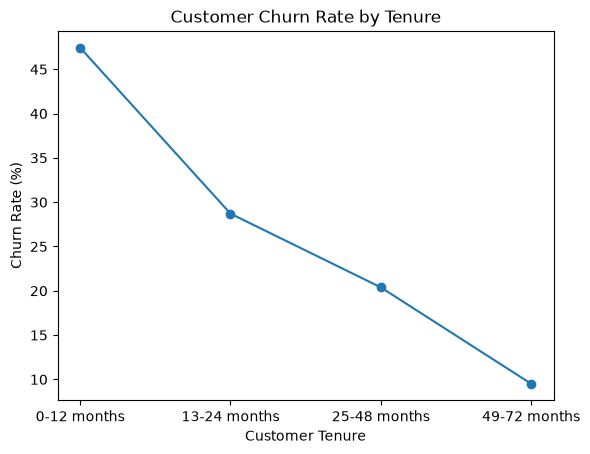

In [ ]:
# Create a line chart of churn rate by tenure group
plt.plot(tenure_churn_rate.index, tenure_churn_rate.values, marker="o")

# Add chart labels and title
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.title("Customer Churn Rate by Tenure")

# Display the chart
plt.show()

### Finding: Churn by Customer Tenure

- 0–12 months: 47.44%
- 13–24 months: 28.71%
- 25–48 months: 20.39%
- 49–72 months: 9.51%

**Business Insight:** Customers in their first 12 months have the highest churn rate. The business should investigate early customer experiences and retention strategies.

**Caveat:** The analysis shows an association between tenure and churn, not causation.

## Monthly Charges Analysis

In [ ]:
# Define monthly charge group boundaries
charge_bins = [0, 50, 85, 120]

# Divide customers into three monthly charge groups
df_clean["ChargeGroup"] = pd.cut(
    df_clean["MonthlyCharges"],
    bins=charge_bins,
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

# Count customers in each charge group
print(df_clean["ChargeGroup"].value_counts().sort_index())

ChargeGroup
Low       2299
Medium    2556
High      2188
Name: count, dtype: int64


In [ ]:
# Filter customers who churned
churned_customers = df_clean[df_clean["Churn"] == "Yes"]

# Count churned customers in each monthly charge group
charge_churn_counts = churned_customers.groupby(
    "ChargeGroup", observed=False
)["Churn"].count()

# Display the results
print(charge_churn_counts)

ChargeGroup
Low       361
Medium    768
High      740
Name: Churn, dtype: int64


In [ ]:
# Count all customers in each monthly charge group
charge_totals = df_clean.groupby("ChargeGroup", observed=False)["Churn"].count()

# Calculate churn rate for each charge group
charge_churn_rate = (charge_churn_counts / charge_totals) * 100

# Display churn rates
print(charge_churn_rate.round(2))

ChargeGroup
Low       15.70
Medium    30.05
High      33.82
Name: Churn, dtype: float64


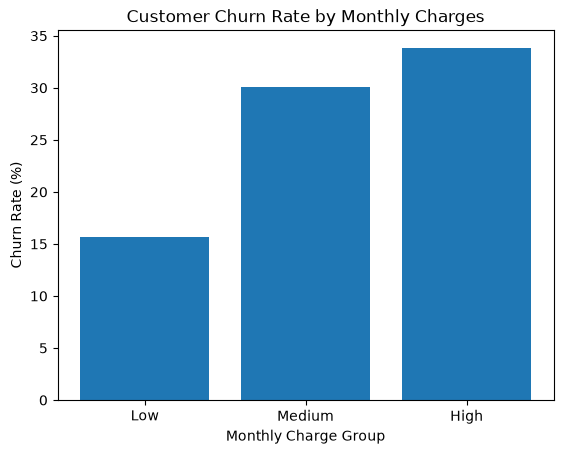

In [ ]:
# Create a bar chart of churn rate by monthly charge group
plt.bar(charge_churn_rate.index, charge_churn_rate.values)

# Add chart labels and title
plt.xlabel("Monthly Charge Group")
plt.ylabel("Churn Rate (%)")
plt.title("Customer Churn Rate by Monthly Charges")

# Display the chart
plt.show()

### Business Interpretation

Customers in the high monthly charge group have the highest churn rate (33.82%), followed by the medium group (30.05%) and low group (15.70%).

This suggests that higher monthly charges are associated with higher customer churn in this dataset.

**Caveat:** This does not prove that higher charges cause customers to leave.

## Churn Analysis by Contract Type

**Business Question:** Which contract type has the highest customer churn rate?

**Method:** Compare the churn percentage across Month-to-month, One year and Two year contracts.

**Visualization:** Bar chart comparing churn rates across contract types.

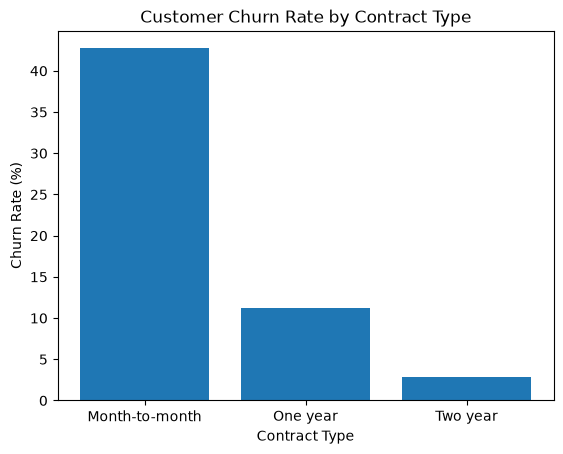

In [ ]:
# Create a bar chart of churn rate by contract type
plt.bar(contract_churn_rate.index, contract_churn_rate.values)

# Add chart labels and title
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.title("Customer Churn Rate by Contract Type")

# Display the chart
plt.show()

## High-Risk Customer Segment Analysis

**Business Question:** What is the churn rate among customers with high monthly charges and month-to-month contracts?

**Method:** Filter customers belonging to both conditions and calculate their churn rate.

In [ ]:
# Filter customers with high monthly charges and month-to-month contracts
high_risk_segment = df_clean[
    (df_clean["MonthlyCharges"] > 85) &
    (df_clean["Contract"] == "Month-to-month")
]

In [ ]:
# Count total customers in this segment
segment_total = len(high_risk_segment)

# Count customers who churned
segment_churned = (high_risk_segment["Churn"] == "Yes").sum()

# Calculate segment churn rate
segment_churn_rate = (segment_churned / segment_total) * 100

# Display the results
print("Total customers:", segment_total)
print("Churned customers:", segment_churned)
print(f"Churn rate: {segment_churn_rate:.2f}%")

Total customers: 1160
Churned customers: 607
Churn rate: 52.33%


### Finding: High-Charge, Month-to-Month Customers

- Total customers: 1,160
- Churned customers: 607
- Churn rate: 52.33%

**Business Insight:** More than half of the customers in this segment have churned. This segment may deserve special attention in customer retention efforts.

**Caveat:** This is a combined segment analysis. We cannot conclude that high charges or month-to-month contracts alone caused churn.

### Visualization: High-Risk Customer Segment

A bar chart comparing churned and retained customers among those with high monthly charges and month-to-month contracts.

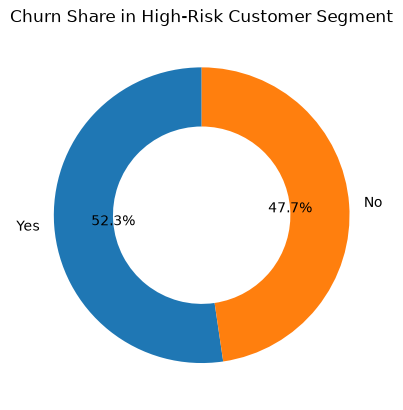

In [ ]:
# Count churned and retained customers in the high-risk segment
segment_counts = high_risk_segment["Churn"].value_counts()

# Create a donut chart
plt.pie(
    segment_counts,
    labels=segment_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

# Add chart title
plt.title("Churn Share in High-Risk Customer Segment")

# Display the chart
plt.show()